# Multi-Agent Cyber-Threat Detection and Response System Using CrewAI and RAG

**Self-contained notebook** - everything (code and knowledge base) is inside this file; no repository is needed.
Runs in Google Colab or local Jupyter.

Pipeline:
1. Generate labelled security telemetry (auth / firewall / web logs) with six injected attacks
2. Detect threats with rules + IsolationForest
3. Build a **RAG** knowledge base (MITRE ATT&CK, CVEs, response playbooks) in ChromaDB
4. Run a **CrewAI** crew: Log Analyst -> Threat-Intel Analyst -> Incident Responder -> Report Writer
5. Evaluate detection and retrieval quality and produce an incident report

**LLM:** add a free `GEMINI_API_KEY` (Google AI Studio) or `GROQ_API_KEY` as a Colab secret (key icon, switch on *Notebook access*).
With no key the notebook runs in **offline mode** (same tools and RAG, deterministic logic).
Source of truth: the `src/cyberthreat` package in the GitHub repo; this notebook is generated from it.

## 1. Install dependencies
Only installs what is missing (about 1-3 minutes on a fresh Colab VM).

In [1]:
import importlib.util, subprocess, sys

REQUIRED = {"crewai": "crewai>=1.0", "chromadb": "chromadb>=0.5", "sklearn": "scikit-learn", "litellm": "litellm",
            "google.genai": "google-genai", "dotenv": "python-dotenv", "matplotlib": "matplotlib", "pandas": "pandas"}
missing = [pkg for mod, pkg in REQUIRED.items() if importlib.util.find_spec(mod.split('.')[0]) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing], check=True)
print("Dependencies ready." if not missing else f"Installed: {missing}")

Dependencies ready.


## 2. Configuration
Paths, `.env` / Colab-secret loading and LLM selection. The provider is auto-detected from whichever API key is set.

In [2]:
import json, re, os
from dataclasses import dataclass, field, asdict
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.ensemble import IsolationForest
from crewai.tools import BaseTool
from pydantic import BaseModel, Field
import warnings; warnings.filterwarnings('ignore')
pd.set_option('display.width', 200); pd.set_option('display.max_colwidth', 90)

In [3]:
"""Central configuration: paths, LLM selection and API-key handling."""
import os
from dataclasses import dataclass
from pathlib import Path

ROOT = Path.cwd()
KB_DIR = ROOT / "knowledge_base"
OUTPUT_DIR = ROOT / "outputs"
CHROMA_DIR = ROOT / "chroma_db"
SEED = 42

DEFAULT_MODELS = {
    "groq": "groq/llama-3.3-70b-versatile",
    "gemini": "gemini/gemini-2.0-flash",
}
KEY_VARS = {"groq": "GROQ_API_KEY", "gemini": "GEMINI_API_KEY"}


def load_env() -> None:
    """Load .env (if python-dotenv is present) and Colab secrets (if running in Colab)."""
    try:
        from dotenv import load_dotenv

        load_dotenv(ROOT / ".env")
    except ImportError:
        pass
    try:  # Google Colab secrets
        from google.colab import userdata  # type: ignore

        for var in (*KEY_VARS.values(), "LLM_PROVIDER", "GROQ_MODEL", "GEMINI_MODEL"):
            if not os.environ.get(var):
                try:
                    os.environ[var] = userdata.get(var)
                except Exception:
                    pass
    except ImportError:
        pass


@dataclass
class LLMSettings:
    provider: str  # groq | gemini | offline
    model: str | None
    api_key: str | None
    note: str = ""

    @property
    def offline(self) -> bool:
        return self.provider == "offline"


def _normalise_model(provider: str, model: str) -> str:
    """Turn 'google/gemma-x', 'models/gemma-x' or 'gemma-x' into the LiteLLM form 'gemini/gemma-x'."""
    model = model.strip()
    for prefix in ("models/", "google/", "gemini/", "groq/"):
        if model.lower().startswith(prefix):
            model = model[len(prefix):]
    return f"{provider}/{model}"


def _infer_provider(text: str) -> str | None:
    t = text.lower()
    if "gemma" in t or "gemini" in t or t.startswith("google/"):
        return "gemini"
    if t.startswith("groq/") or "llama" in t or "mixtral" in t:
        return "groq"
    return None


def get_llm_settings(provider: str | None = None) -> LLMSettings:
    """Resolve the LLM backend.

    ``LLM_PROVIDER`` may be ``groq``, ``gemini``, ``offline`` or empty (auto: use whichever API key is set).
    If it holds a model name (e.g. ``google/gemma-4-26B-A4B-it``) it is treated as the model ID.
    Falls back to ``offline`` when no usable API key is found.
    """
    load_env()
    raw = (provider or os.environ.get("LLM_PROVIDER") or "").strip()
    low, model_override, note = raw.lower(), None, ""
    if low == "offline":
        return LLMSettings("offline", None, None, "LLM_PROVIDER=offline")
    if low in KEY_VARS:
        chosen = low
    else:
        chosen = None
        if low not in ("", "auto"):  # a model name was supplied instead of a provider
            model_override = raw
            chosen = _infer_provider(raw)
            note = f"LLM_PROVIDER='{raw}' is not a provider; treating it as the model ID. "
        if chosen is None:  # auto-detect from whichever key exists
            chosen = next((p for p, var in KEY_VARS.items() if os.environ.get(var)), "groq")
    key = os.environ.get(KEY_VARS[chosen])
    if not key:
        other = next((p for p, var in KEY_VARS.items() if os.environ.get(var)), None)
        hint = f" (a {KEY_VARS[other]} exists - set LLM_PROVIDER={other})" if other else ""
        missing = f"No {KEY_VARS[chosen]} found{hint}" if other else "No GEMINI_API_KEY or GROQ_API_KEY found"
        return LLMSettings("offline", None, None, f"{note}{missing}; running offline.")
    model = model_override or os.environ.get(f"{chosen.upper()}_MODEL") or DEFAULT_MODELS[chosen]
    return LLMSettings(chosen, _normalise_model(chosen, model), key, note.strip())


def list_gemini_models(api_key: str | None = None) -> list[str]:
    """IDs of models your Gemini/AI Studio key can call with generateContent (copy one into GEMINI_MODEL)."""
    import json
    import urllib.request

    load_env()
    api_key = api_key or os.environ.get("GEMINI_API_KEY")
    if not api_key:
        raise RuntimeError("GEMINI_API_KEY is not set")
    names, token = [], ""
    while True:
        url = "https://generativelanguage.googleapis.com/v1beta/models?pageSize=200" + (f"&pageToken={token}" if token else "")
        req = urllib.request.Request(url, headers={"x-goog-api-key": api_key})
        with urllib.request.urlopen(req, timeout=30) as r:
            data = json.load(r)
        names += [m["name"].removeprefix("models/") for m in data.get("models", [])
                  if "generateContent" in m.get("supportedGenerationMethods", [])]
        token = data.get("nextPageToken", "")
        if not token:
            return sorted(names)


def build_llm(settings: LLMSettings | None = None):
    """Create a CrewAI ``LLM`` for the chosen provider (None when offline)."""
    settings = settings or get_llm_settings()
    if settings.offline:
        return None
    from crewai import LLM

    return LLM(model=settings.model, api_key=settings.api_key, temperature=0.1)

## 3. Embedded knowledge base
MITRE ATT&CK techniques, CVE samples, an IOC feed and six incident-response playbooks are stored here as text and written to `knowledge_base/` so the RAG layer can index them. Edit or add entries to extend the system.

In [4]:
KB_FILES = {
    "cve_samples.json": r'''[
  {
    "id": "CVE-2021-41773",
    "description": "Apache HTTP Server 2.4.49 path traversal allowing file disclosure and remote code execution.",
    "mitre_id": "T1190",
    "remediation": "Upgrade Apache to 2.4.51 or later."
  },
  {
    "id": "CVE-2018-15473",
    "description": "OpenSSH username enumeration through timing differences, aiding SSH brute force attacks.",
    "mitre_id": "T1110",
    "remediation": "Upgrade OpenSSH and enforce key-based authentication."
  },
  {
    "id": "CVE-2021-3156",
    "description": "Sudo heap-based buffer overflow (Baron Samedit) enabling local privilege escalation to root.",
    "mitre_id": "T1548",
    "remediation": "Upgrade sudo to 1.9.5p2 or later."
  },
  {
    "id": "CVE-2019-11043",
    "description": "PHP-FPM remote code execution under certain nginx configurations.",
    "mitre_id": "T1190",
    "remediation": "Update PHP-FPM and fix nginx fastcgi configuration."
  },
  {
    "id": "CVE-2022-22965",
    "description": "Spring4Shell remote code execution in Spring Framework via data binding.",
    "mitre_id": "T1190",
    "remediation": "Upgrade Spring Framework to 5.3.18 or later."
  }
]''',
    "ioc_feed.json": r'''[
 {"ip":"185.220.101.7","type":"c2_server","confidence":"high","note":"Known botnet C2 / Tor exit node"},
 {"ip":"45.133.1.88","type":"exfil_destination","confidence":"high","note":"Bulletproof hosting used for data staging"},
 {"ip":"203.0.113.45","type":"brute_forcer","confidence":"medium","note":"Reported for SSH credential stuffing"},
 {"ip":"198.51.100.77","type":"scanner","confidence":"medium","note":"Mass internet scanner"},
 {"ip":"203.0.113.99","type":"web_attacker","confidence":"medium","note":"Automated SQLi tooling"}
]''',
    "mitre_attack_techniques.json": r'''[
  {
    "id": "T1110",
    "name": "Brute Force",
    "tactic": "Credential Access",
    "description": "Adversaries guess passwords or use credential lists to gain access to accounts. Repeated failed SSH or RDP logins from a single source across many usernames, sometimes followed by a successful login, are typical indicators.",
    "mitigation": "Enforce account lockout and rate limiting, use multi-factor authentication, disable password SSH in favour of keys, deploy fail2ban."
  },
  {
    "id": "T1046",
    "name": "Network Service Discovery",
    "tactic": "Discovery",
    "description": "Adversaries scan hosts for open ports and listening services to find targets. Many connection attempts to sequential or random ports from one IP, mostly denied by the firewall, indicate a port scan.",
    "mitigation": "Restrict network exposure, segment networks, block scanning sources, enable IDS scan detection."
  },
  {
    "id": "T1190",
    "name": "Exploit Public-Facing Application",
    "tactic": "Initial Access",
    "description": "Adversaries exploit weaknesses in internet-facing applications such as SQL injection, where malicious SQL like UNION SELECT, OR 1=1 or DROP TABLE is inserted in request parameters to read or modify the database.",
    "mitigation": "Use parameterised queries, input validation, a web application firewall, patch applications and apply least-privilege database accounts."
  },
  {
    "id": "T1071",
    "name": "Application Layer Protocol",
    "tactic": "Command and Control",
    "description": "Adversaries communicate with compromised systems over common protocols to blend with normal traffic. Beaconing is periodic, near-constant-interval, small outbound connections to an external command-and-control server.",
    "mitigation": "Block known C2 infrastructure, use egress filtering and DNS/proxy inspection, detect periodic beaconing, isolate infected hosts."
  },
  {
    "id": "T1041",
    "name": "Exfiltration Over C2 Channel",
    "tactic": "Exfiltration",
    "description": "Adversaries steal data by sending it over an existing command-and-control channel. Unusually large outbound transfers to a rare external destination indicate data exfiltration.",
    "mitigation": "Apply data loss prevention, egress traffic limits and monitoring, block the destination, isolate the source host and preserve evidence."
  },
  {
    "id": "T1548",
    "name": "Abuse Elevation Control Mechanism",
    "tactic": "Privilege Escalation",
    "description": "Adversaries circumvent elevation controls to gain higher privileges, for example setting the setuid bit with chmod u+s, editing /etc/sudoers with NOPASSWD, or adding a user to the sudo group.",
    "mitigation": "Audit sudoers, monitor setuid changes, enforce least privilege, require re-authentication for sudo and alert on privilege changes."
  },
  {
    "id": "T1078",
    "name": "Valid Accounts",
    "tactic": "Initial Access",
    "description": "Adversaries obtain and use legitimate credentials. A successful login after many failures or logins from unusual locations can indicate compromised valid accounts.",
    "mitigation": "Rotate credentials, enforce MFA, review account activity and disable compromised accounts."
  },
  {
    "id": "T1595",
    "name": "Active Scanning",
    "tactic": "Reconnaissance",
    "description": "Adversaries probe victim infrastructure to gather information. Statistically anomalous, high-volume traffic from a single source may indicate reconnaissance.",
    "mitigation": "Rate-limit and block abusive sources, monitor for anomalies and review exposed services."
  },
  {
    "id": "T1059",
    "name": "Command and Scripting Interpreter",
    "tactic": "Execution",
    "description": "Adversaries abuse shells and scripting interpreters such as bash or PowerShell to execute commands.",
    "mitigation": "Restrict interpreters, enable command-line auditing and application allow-listing."
  },
  {
    "id": "T1486",
    "name": "Data Encrypted for Impact",
    "tactic": "Impact",
    "description": "Adversaries encrypt data to interrupt availability, typically ransomware, with mass file modification and ransom notes.",
    "mitigation": "Maintain offline backups, segment networks, use EDR and isolate affected hosts."
  }
]''',
    "playbooks/c2_beaconing.md": r'''# Playbook: Command-and-Control Beaconing (T1071)
**Severity:** Critical

## Detection indicators
- A host connects to the same external IP at near-constant intervals with small payloads.

## Containment
1. Isolate the infected host from the network immediately.
2. Block the C2 IP address and domain at the firewall and DNS.

## Eradication and recovery
1. Capture memory and disk evidence, then reimage the host.
2. Hunt for the same indicators on other hosts and rotate credentials used on the host.

## Post-incident
Share indicators of compromise with threat intelligence and review egress filtering.''',
    "playbooks/data_exfiltration.md": r'''# Playbook: Data Exfiltration (T1041)
**Severity:** Critical

## Detection indicators
- Large outbound transfers (tens of MB) from an internal server to a rare external IP.

## Containment
1. Block the destination IP and isolate the source host.
2. Preserve network and host evidence.

## Eradication and recovery
1. Identify the data accessed and the compromised accounts; rotate their credentials.
2. Assess breach notification obligations with legal and compliance teams.

## Post-incident
Deploy DLP controls and egress volume alerting.''',
    "playbooks/port_scan.md": r'''# Playbook: Port Scan / Network Reconnaissance (T1046)
**Severity:** Medium

## Detection indicators
- One source IP probing many distinct destination ports, mostly denied by the firewall.

## Containment
1. Block the scanning source IP at the firewall.
2. Check whether any probe was allowed, and verify the exposed services.

## Recovery
1. Close unnecessary open ports and restrict services to required networks.
2. Watch for follow-up exploitation attempts from the same source.

## Post-incident
Add the source to threat intelligence blocklists and tune IDS thresholds.''',
    "playbooks/privilege_escalation.md": r'''# Playbook: Privilege Escalation (T1548)
**Severity:** Critical

## Detection indicators
- chmod u+s on shells, edits to /etc/sudoers with NOPASSWD, usermod -aG sudo, sudo to /bin/bash.

## Containment
1. Disable the user account and kill its sessions.
2. Isolate the host if root compromise is suspected.

## Eradication and recovery
1. Revert sudoers and setuid changes; audit for backdoor accounts and persistence.
2. Patch local privilege escalation vulnerabilities such as sudo CVE-2021-3156.

## Post-incident
Enforce least privilege and enable auditd rules for privilege changes.''',
    "playbooks/sql_injection.md": r'''# Playbook: SQL Injection (T1190)
**Severity:** High

## Detection indicators
- Web requests containing UNION SELECT, OR 1=1, DROP TABLE, SLEEP() or information_schema.

## Containment
1. Block the attacking IP on the web application firewall.
2. Check database logs to determine whether data was read or modified.

## Eradication and recovery
1. Patch the vulnerable endpoint with parameterised queries and input validation.
2. Rotate database credentials and restore data from backup if it was modified.

## Post-incident
Run a vulnerability scan on the application and notify stakeholders if personal data was exposed.''',
    "playbooks/ssh_brute_force.md": r'''# Playbook: SSH Brute Force (T1110)
**Severity:** High

## Detection indicators
- Many failed SSH logins from one source IP in a short period, across multiple usernames.
- A successful login following the failures indicates possible account compromise.

## Containment
1. Block the offending source IP at the perimeter firewall.
2. If a login succeeded, disable the affected account and terminate its active sessions.

## Eradication and recovery
1. Reset credentials of the affected account and review it for persistence (authorized_keys, cron).
2. Enforce MFA or key-only SSH authentication; deploy fail2ban rate limiting.

## Post-incident
Review auth logs for other sources, document lessons learned.''',
}

for rel, text in KB_FILES.items():
    path = KB_DIR / rel
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(text)
print(f'Wrote {len(KB_FILES)} knowledge-base files to {KB_DIR}')

Wrote 9 knowledge-base files to /tmp/claude-0/-home-user-cyber-threat/8089c010-090e-56e5-8031-3d5df1b25712/scratchpad/run/knowledge_base


## 4. Security telemetry generator
Three log sources in one schema; `label` is ground truth used only for evaluation.

In [5]:
"""Synthetic, labelled security telemetry (auth, firewall and web logs).

All sources share one schema so that detection code stays simple:

    event_id, timestamp, source, src_ip, dst_ip, dst_port, host, user,
    action, bytes_out, request, status, label

``label`` is ``benign`` or the injected attack type (ground truth for evaluation).
"""
import numpy as np
import pandas as pd


ATTACK_TYPES = [
    "ssh_brute_force",
    "port_scan",
    "sql_injection",
    "c2_beaconing",
    "data_exfiltration",
    "privilege_escalation",
]

COLUMNS = [
    "event_id", "timestamp", "source", "src_ip", "dst_ip", "dst_port",
    "host", "user", "action", "bytes_out", "request", "status", "label",
]

HOSTS = {"web-01": "10.0.1.10", "db-01": "10.0.2.20", "app-01": "10.0.1.30", "files-01": "10.0.3.40"}
USERS = ["alice", "bob", "carol", "dave", "erin", "svc_backup"]
WORKSTATIONS = [f"10.0.5.{i}" for i in range(11, 31)]
BENIGN_PATHS = ["/", "/index.html", "/products", "/products?id=12", "/login", "/about", "/api/v1/items", "/static/app.js"]
SQLI_PAYLOADS = [
    "/products?id=1' OR '1'='1", "/products?id=1 UNION SELECT username,password FROM users--",
    "/login?user=admin'--", "/products?id=1; DROP TABLE users;--",
    "/api/v1/items?id=1 AND SLEEP(5)", "/products?id=1 UNION SELECT table_name FROM information_schema.tables",
]
BASE_TIME = pd.Timestamp("2026-03-01 08:00:00")


def _row(ts, source, src_ip, dst_ip, dst_port, host, user, action, bytes_out, request, status, label):
    return dict(timestamp=ts, source=source, src_ip=src_ip, dst_ip=dst_ip, dst_port=int(dst_port),
                host=host, user=user, action=action, bytes_out=int(bytes_out), request=request,
                status=status, label=label)


def _benign(rng: np.random.RandomState, n: int, span_s: int) -> list[dict]:
    rows = []
    for _ in range(n):
        ts = BASE_TIME + pd.Timedelta(seconds=int(rng.randint(0, span_s)))
        kind = rng.choice(["auth", "web", "fw"], p=[0.25, 0.4, 0.35])
        host = rng.choice(list(HOSTS))
        if kind == "auth":
            ok = rng.rand() > 0.04
            rows.append(_row(ts, "auth", rng.choice(WORKSTATIONS), HOSTS[host], 22, host, rng.choice(USERS),
                             "login_success" if ok else "login_failed", rng.randint(100, 900),
                             "sshd: session opened" if ok else "sshd: authentication failure",
                             "success" if ok else "failure", "benign"))
        elif kind == "web":
            rows.append(_row(ts, "web", f"192.0.2.{rng.randint(1, 200)}", HOSTS["web-01"], 443, "web-01", "-",
                             "http_request", rng.randint(500, 40_000), "GET " + rng.choice(BENIGN_PATHS),
                             str(rng.choice([200, 200, 200, 304, 404])), "benign"))
        else:
            src = rng.choice(WORKSTATIONS)
            port = int(rng.choice([80, 443, 443, 53, 8080]))
            ext = f"93.184.{rng.randint(1, 50)}.{rng.randint(1, 250)}"
            rows.append(_row(ts, "firewall", src, ext, port, "fw-edge", "-", "allow",
                             rng.randint(500, 2_000_000), f"tcp/{port}", "allowed", "benign"))
    return rows


def _ssh_brute_force(rng, start: pd.Timestamp) -> list[dict]:
    ip, host, rows = "203.0.113.45", "web-01", []
    for i in range(70):
        rows.append(_row(start + pd.Timedelta(seconds=i * 1.5), "auth", ip, HOSTS[host], 22, host,
                         rng.choice(["root", "admin", "alice", "test", "oracle", "ubuntu"]), "login_failed",
                         200, "sshd: authentication failure", "failure", "ssh_brute_force"))
    rows.append(_row(start + pd.Timedelta(seconds=110), "auth", ip, HOSTS[host], 22, host, "alice",
                     "login_success", 300, "sshd: session opened", "success", "ssh_brute_force"))
    return rows


def _port_scan(rng, start: pd.Timestamp) -> list[dict]:
    ip, host = "198.51.100.77", "db-01"
    ports = rng.choice(np.arange(1, 10000), 60, replace=False)
    return [_row(start + pd.Timedelta(seconds=i * 0.4), "firewall", ip, HOSTS[host], p, host, "-", "deny", 60,
                 f"tcp/{p} SYN", "blocked", "port_scan") for i, p in enumerate(ports)]


def _sql_injection(rng, start: pd.Timestamp) -> list[dict]:
    ip = "203.0.113.99"
    return [_row(start + pd.Timedelta(seconds=i * 6), "web", ip, HOSTS["web-01"], 443, "web-01", "-",
                 "http_request", rng.randint(2_000, 90_000), "GET " + SQLI_PAYLOADS[i % len(SQLI_PAYLOADS)],
                 str(rng.choice([200, 500])), "sql_injection") for i in range(12)]


def _c2_beaconing(rng, start: pd.Timestamp) -> list[dict]:
    src, c2 = "10.0.5.23", "185.220.101.7"
    return [_row(start + pd.Timedelta(seconds=i * 60 + rng.uniform(-1, 1)), "firewall", src, c2, 4444,
                 "fw-edge", "-", "allow", rng.randint(180, 260), "tcp/4444", "allowed", "c2_beaconing")
            for i in range(40)]


def _exfiltration(rng, start: pd.Timestamp) -> list[dict]:
    src, dst = "10.0.3.40", "45.133.1.88"
    return [_row(start + pd.Timedelta(seconds=i * 30), "firewall", src, dst, 443, "fw-edge", "-", "allow",
                 rng.randint(25_000_000, 60_000_000), "tcp/443 upload", "allowed", "data_exfiltration")
            for i in range(8)]


def _priv_esc(rng, start: pd.Timestamp) -> list[dict]:
    host, ip = "app-01", HOSTS["app-01"]
    cmds = ["sudo: bob : COMMAND=/bin/bash", "chmod u+s /bin/bash",
            "echo 'bob ALL=(ALL) NOPASSWD:ALL' >> /etc/sudoers", "usermod -aG sudo bob", "su root"]
    return [_row(start + pd.Timedelta(seconds=i * 20), "auth", "10.0.5.14", ip, 22, host, "bob",
                 "privilege_change", 150, c, "success", "privilege_escalation") for i, c in enumerate(cmds)]


def generate_logs(n_benign: int = 2500, span_s: int = 3 * 3600, seed: int = SEED) -> pd.DataFrame:
    """Return a time-sorted DataFrame of benign noise plus one injected incident per attack type."""
    rng = np.random.RandomState(seed)
    rows = _benign(rng, n_benign, span_s)
    injectors = [_ssh_brute_force, _port_scan, _sql_injection, _c2_beaconing, _exfiltration, _priv_esc]
    for k, inj in enumerate(injectors):
        start = BASE_TIME + pd.Timedelta(minutes=15 + k * 22)
        rows.extend(inj(rng, start))
    df = pd.DataFrame(rows).sort_values("timestamp").reset_index(drop=True)
    df.insert(0, "event_id", np.arange(len(df)))
    return df[COLUMNS]

## 5. Detection layer
Rule-based detectors (thresholds, signatures, beacon periodicity) plus IsolationForest for unexplained outliers.

In [6]:
"""Detection layer: signature/threshold rules + IsolationForest anomaly scoring."""
import re
from dataclasses import dataclass, field, asdict

import numpy as np
import pandas as pd
from sklearn.ensemble import IsolationForest


SQLI_RE = re.compile(
    r"(union\s+select|'\s*or\s*'|\bor\s+1\s*=\s*1|--|;\s*drop\s+table|sleep\s*\(|information_schema)", re.I)
PRIVESC_RE = re.compile(r"(chmod\s+u\+s|/etc/sudoers|usermod\s+-aG\s+sudo|NOPASSWD|COMMAND=/bin/bash|su\s+root)", re.I)

MITRE_MAP = {
    "ssh_brute_force": "T1110", "port_scan": "T1046", "sql_injection": "T1190",
    "c2_beaconing": "T1071", "data_exfiltration": "T1041", "privilege_escalation": "T1548",
    "anomalous_activity": "T1595",
}
SEVERITY = {
    "ssh_brute_force": "High", "port_scan": "Medium", "sql_injection": "High",
    "c2_beaconing": "Critical", "data_exfiltration": "Critical", "privilege_escalation": "Critical",
    "anomalous_activity": "Low",
}


@dataclass
class Alert:
    alert_id: str
    attack_type: str
    severity: str
    src_ip: str
    host: str
    method: str  # rule | anomaly
    description: str
    mitre_id: str
    first_seen: str
    last_seen: str
    event_ids: list = field(default_factory=list)
    threat_ip: str = ""  # remote malicious party to block (empty if none, e.g. insider/anomaly)

    def to_dict(self) -> dict:
        d = asdict(self)
        d["event_count"] = len(self.event_ids)
        return d


def _mk(idx: int, atype: str, src: str, host: str, method: str, desc: str, ev: pd.DataFrame,
        threat_ip: str = "") -> Alert:
    fmt = "%Y-%m-%d %H:%M:%S"
    return Alert(f"ALERT-{idx:03d}", atype, SEVERITY[atype], src, host, method, desc, MITRE_MAP[atype],
                 ev.timestamp.min().strftime(fmt), ev.timestamp.max().strftime(fmt),
                 [int(i) for i in ev.event_id], threat_ip)


def rule_detect(df: pd.DataFrame) -> list[Alert]:
    """Deterministic signatures and thresholds, one alert per offending source."""
    alerts: list[Alert] = []
    n = lambda: len(alerts) + 1  # noqa: E731

    # SSH brute force: >=10 failed logins from one IP within 5 minutes
    failed = df[(df.source == "auth") & (df.action == "login_failed")]
    for ip, g in failed.groupby("src_ip"):
        g = g.sort_values("timestamp")
        if len(g) >= 10 and (g.timestamp.max() - g.timestamp.min()) <= pd.Timedelta(minutes=5):
            ok = df[(df.src_ip == ip) & (df.action == "login_success")]
            ev = pd.concat([g, ok]).sort_values("timestamp")
            extra = " followed by a SUCCESSFUL login (possible compromise)" if len(ok) else ""
            alerts.append(_mk(n(), "ssh_brute_force", ip, g.host.iloc[0], "rule",
                              f"{len(g)} failed SSH logins in {(g.timestamp.max()-g.timestamp.min()).seconds}s "
                              f"across {g.user.nunique()} accounts{extra}", ev, threat_ip=ip))

    # Port scan: >=20 distinct destination ports denied by firewall from one IP
    fw = df[(df.source == "firewall") & (df.action == "deny")]
    for ip, g in fw.groupby("src_ip"):
        if g.dst_port.nunique() >= 20:
            alerts.append(_mk(n(), "port_scan", ip, g.host.iloc[0], "rule",
                              f"{g.dst_port.nunique()} distinct ports probed on {g.dst_ip.iloc[0]}", g, threat_ip=ip))

    # SQL injection: web requests with SQLi signatures
    web = df[df.source == "web"]
    hits = web[web.request.str.contains(SQLI_RE)]
    for ip, g in hits.groupby("src_ip"):
        alerts.append(_mk(n(), "sql_injection", ip, "web-01", "rule",
                          f"{len(g)} requests containing SQL-injection payloads", g, threat_ip=ip))

    allowed = df[(df.source == "firewall") & (df.action == "allow")]
    # C2 beaconing: >=15 connections to one external IP with near-constant interval and small payloads
    for (src, dst), g in allowed.groupby(["src_ip", "dst_ip"]):
        if len(g) < 15:
            continue
        gaps = g.sort_values("timestamp").timestamp.diff().dt.total_seconds().dropna()
        if gaps.mean() > 0 and gaps.std() / gaps.mean() < 0.1 and g.bytes_out.median() < 5_000:
            alerts.append(_mk(n(), "c2_beaconing", src, "fw-edge", "rule",
                              f"{len(g)} connections to {dst}:{g.dst_port.iloc[0]} every ~{gaps.mean():.0f}s "
                              f"(jitter {gaps.std():.1f}s)", g, threat_ip=dst))

    # Data exfiltration: > 100 MB uploaded to one external destination
    for (src, dst), g in allowed.groupby(["src_ip", "dst_ip"]):
        total = g.bytes_out.sum()
        if total > 100_000_000:
            alerts.append(_mk(n(), "data_exfiltration", src, "fw-edge", "rule",
                              f"{total/1e6:.0f} MB sent to {dst} in {len(g)} flows", g, threat_ip=dst))

    # Privilege escalation: suspicious privilege-change commands
    pc = df[(df.action == "privilege_change") & df.request.str.contains(PRIVESC_RE)]
    for ip, g in pc.groupby("src_ip"):
        alerts.append(_mk(n(), "privilege_escalation", ip, g.host.iloc[0], "rule",
                          f"{len(g)} suspicious privilege commands by user '{g.user.iloc[0]}'", g))
    return alerts


def _features(df: pd.DataFrame, window: str = "5min") -> pd.DataFrame:
    d = df.copy()
    d["win"] = d.timestamp.dt.floor(window)
    g = d.groupby(["src_ip", "win"])
    feat = pd.DataFrame({
        "n_events": g.size(),
        "n_failed": g.apply(lambda x: (x.status.isin(["failure", "blocked"])).sum(), include_groups=False),
        "n_ports": g.dst_port.nunique(),
        "bytes_out": g.bytes_out.sum(),
        "n_targets": g.dst_ip.nunique(),
    })
    return feat


def anomaly_detect(df: pd.DataFrame, contamination: float = 0.002, seed: int = SEED,
                   exclude_events: set | None = None) -> list[Alert]:
    """IsolationForest over per-(source IP, 5-min window) behaviour; flags unexplained outliers."""
    feat = _features(df)
    X = np.log1p(feat.values.astype(float))
    model = IsolationForest(n_estimators=200, contamination=contamination, random_state=seed).fit(X)
    flagged = feat[model.predict(X) == -1]
    alerts, exclude = [], exclude_events or set()
    for (ip, win), _ in flagged.iterrows():
        ev = df[(df.src_ip == ip) & (df.timestamp.dt.floor("5min") == win)]
        if set(ev.event_id) <= exclude:
            continue  # already explained by a rule alert
        alerts.append(_mk(len(alerts) + 1, "anomalous_activity", ip, ev.host.iloc[0], "anomaly",
                          f"Statistically anomalous behaviour: {len(ev)} events, "
                          f"{ev.dst_port.nunique()} ports, {ev.bytes_out.sum()/1e3:.0f} KB out", ev))
    return alerts


def detect_all(df: pd.DataFrame, use_anomaly: bool = True) -> list[Alert]:
    """Run rules, then anomaly detection on whatever the rules did not explain."""
    alerts = rule_detect(df)
    if use_anomaly:
        covered = {e for a in alerts for e in a.event_ids}
        extra = anomaly_detect(df, exclude_events=covered)
        for a in extra:
            a.alert_id = f"ALERT-{len(alerts) + 1:03d}"
            alerts.append(a)
    return alerts


def alerts_to_frame(alerts: list[Alert]) -> pd.DataFrame:
    cols = ["alert_id", "attack_type", "severity", "src_ip", "host", "method", "mitre_id", "event_count", "description"]
    return pd.DataFrame([a.to_dict() for a in alerts], columns=cols + ["first_seen", "last_seen", "event_ids"])[cols]

## 6. RAG layer
Chunking, embeddings (MiniLM when available, TF-IDF hashing otherwise) and a ChromaDB vector store.

In [7]:
"""Retrieval-Augmented Generation layer: knowledge-base loading, chunking, embedding, ChromaDB search."""
import json
import re
from dataclasses import dataclass

import numpy as np



@dataclass
class Chunk:
    id: str
    text: str
    metadata: dict


class Embedder:
    """Sentence-transformers (all-MiniLM-L6-v2) when available, else a TF-IDF-style hashing embedding."""

    def __init__(self, prefer_transformer: bool = True):
        self.name = "hashing-tfidf"
        self._st = None
        if prefer_transformer:
            try:
                from sentence_transformers import SentenceTransformer

                self._st = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
                self.name = "all-MiniLM-L6-v2"
            except Exception:
                self._st = None
        if self._st is None:
            from sklearn.feature_extraction.text import HashingVectorizer

            self._hv = HashingVectorizer(n_features=1024, alternate_sign=False, norm="l2",
                                         ngram_range=(1, 2), stop_words="english")

    def encode(self, texts: list[str]) -> list[list[float]]:
        if self._st is not None:
            return self._st.encode(texts, normalize_embeddings=True).tolist()
        return self._hv.transform(texts).toarray().astype(float).tolist()


def load_chunks(kb_dir=KB_DIR) -> list[Chunk]:
    chunks: list[Chunk] = []
    for t in json.load(open(kb_dir / "mitre_attack_techniques.json")):
        text = (f"{t['id']} {t['name']} ({t['tactic']}). {t['description']} Mitigation: {t['mitigation']}")
        chunks.append(Chunk(f"mitre-{t['id']}", text, {"doc_type": "mitre", "mitre_id": t["id"], "title": t["name"]}))
    for c in json.load(open(kb_dir / "cve_samples.json")):
        chunks.append(Chunk(f"cve-{c['id']}", f"{c['id']}: {c['description']} Remediation: {c['remediation']}",
                            {"doc_type": "cve", "mitre_id": c["mitre_id"], "title": c["id"]}))
    for p in sorted((kb_dir / "playbooks").glob("*.md")):
        raw = p.read_text()
        title = raw.splitlines()[0].lstrip("# ").strip()
        m = re.search(r"T\d{4}", title)
        mid = m.group(0) if m else ""
        for i, sec in enumerate(re.split(r"\n(?=## )", raw)[1:] or [raw]):
            chunks.append(Chunk(f"playbook-{p.stem}-{i}", f"{title}\n{sec.strip()}",
                                {"doc_type": "playbook", "mitre_id": mid, "title": title, "playbook": p.stem}))
    return chunks


class KnowledgeBase:
    """ChromaDB-backed vector store with cosine similarity search."""

    def __init__(self, persist_dir=None, embedder: Embedder | None = None, rebuild: bool = True):
        import chromadb

        self.embedder = embedder or Embedder()
        self.client = chromadb.PersistentClient(path=str(persist_dir or CHROMA_DIR))
        name = "security_kb"
        if rebuild:
            try:
                self.client.delete_collection(name)
            except Exception:
                pass
        self.col = self.client.get_or_create_collection(name, metadata={"hnsw:space": "cosine"})
        if self.col.count() == 0:
            chunks = load_chunks()
            self.col.add(ids=[c.id for c in chunks], documents=[c.text for c in chunks],
                         metadatas=[c.metadata for c in chunks], embeddings=self.embedder.encode([c.text for c in chunks]))

    def search(self, query: str, k: int = 3, doc_type: str | None = None) -> list[dict]:
        res = self.col.query(query_embeddings=self.embedder.encode([query]), n_results=k,
                             where={"doc_type": doc_type} if doc_type else None)
        return [{"id": i, "text": d, "metadata": m, "score": round(1 - float(dist), 3)}
                for i, d, m, dist in zip(res["ids"][0], res["documents"][0], res["metadatas"][0], res["distances"][0])]


    def get_playbook(self, stem: str) -> str:
        """Return a full playbook (all its chunks in order) by file stem."""
        res = self.col.get(where={"playbook": stem})
        return "\n\n".join(d for _, d in sorted(zip(res["ids"], res["documents"])))


def retrieval_hit_rate(kb: KnowledgeBase, cases: list[tuple[str, str]], k: int = 3) -> float:
    """Fraction of (query, expected_mitre_id) pairs whose top-k results contain the expected technique."""
    hits = sum(any(r["metadata"].get("mitre_id") == exp for r in kb.search(q, k)) for q, exp in cases)
    return hits / len(cases)

## 7. Agent tools
Plain functions plus CrewAI `BaseTool` wrappers. Response actions are **simulated** and restricted to an allow-list.

In [8]:
"""Agent tools. Plain functions hold the logic; thin CrewAI ``BaseTool`` wrappers expose them to agents.

All tools read/write a shared :class:`SecurityContext` (logs, alerts, knowledge base, simulated action log).
Response actions are SIMULATED - they are only recorded, never executed.
"""
import json
from dataclasses import dataclass, field
from datetime import datetime

import pandas as pd
from crewai.tools import BaseTool
from pydantic import BaseModel, Field


ALLOWED_ACTIONS = {"block_ip", "isolate_host", "disable_account", "reset_credentials", "enable_waf_rule", "create_ticket"}


@dataclass
class SecurityContext:
    logs: pd.DataFrame | None = None
    kb: KnowledgeBase | None = None
    alerts: list[Alert] = field(default_factory=list)
    actions: list[dict] = field(default_factory=list)
    ioc_feed: dict = field(default_factory=dict)

    def __post_init__(self):
        self.ioc_feed = {i["ip"]: i for i in json.load(open(KB_DIR / "ioc_feed.json"))}


CTX = SecurityContext()  # shared by all tools; set via crew.setup_context()


# ---- plain functions -------------------------------------------------------------------------------------------
def analyze_logs() -> str:
    CTX.alerts = rule_detect(CTX.logs)
    return _summarise(CTX.alerts)


def detect_anomalies() -> str:
    covered = {e for a in CTX.alerts for e in a.event_ids}
    extra = anomaly_detect(CTX.logs, exclude_events=covered)
    for a in extra:
        a.alert_id = f"ALERT-{len(CTX.alerts) + 1:03d}"
        CTX.alerts.append(a)
    return _summarise(extra) if extra else "No additional anomalies beyond rule-based alerts."


def _summarise(alerts: list[Alert]) -> str:
    return json.dumps([{k: v for k, v in a.to_dict().items() if k not in ("event_ids", "first_seen", "last_seen")}
                       for a in alerts], indent=1)


def search_threat_intel(query: str) -> str:
    hits = CTX.kb.search(query, k=2, doc_type="mitre") + CTX.kb.search(query, k=1, doc_type="cve")
    return "\n".join(f"[{h['metadata']['title']} | {h['metadata'].get('mitre_id','')} | score {h['score']}] {h['text']}"
                     for h in hits)


def lookup_ioc(ip: str) -> str:
    feed = CTX.ioc_feed.get(ip)
    ev = CTX.logs[CTX.logs.src_ip.eq(ip) | CTX.logs.dst_ip.eq(ip)]
    internal = ip.startswith("10.")
    return json.dumps({"ip": ip, "internal": internal, "threat_feed_match": feed or "none",
                       "events_in_logs": int(len(ev)),
                       "first_seen": str(ev.timestamp.min()) if len(ev) else None})


def search_playbook(query: str) -> str:
    top = CTX.kb.search(query, k=1, doc_type="playbook")[0]
    return CTX.kb.get_playbook(top["metadata"]["playbook"])


def take_response_action(action: str, target: str, reason: str) -> str:
    if action not in ALLOWED_ACTIONS:
        return f"REJECTED: '{action}' not in {sorted(ALLOWED_ACTIONS)}"
    if any(a["action"] == action and a["target"] == target for a in CTX.actions):
        return f"SKIPPED: {action} on {target} already recorded"
    rec = {"time": datetime.now().isoformat(timespec="seconds"), "action": action, "target": target,
           "reason": reason, "mode": "SIMULATED"}
    CTX.actions.append(rec)
    return f"[SIMULATED] {action} applied to {target}"


# ---- CrewAI wrappers -------------------------------------------------------------------------------------------
class _NoArgs(BaseModel):
    pass


class _Query(BaseModel):
    query: str = Field(..., description="Natural-language description of the threat or behaviour")


class _IP(BaseModel):
    ip: str = Field(..., description="IP address to look up")


class _Action(BaseModel):
    action: str = Field(..., description=f"One of {sorted(ALLOWED_ACTIONS)}")
    target: str = Field(..., description="IP address, hostname or account name")
    reason: str = Field(..., description="Short justification")


class LogAnalysisTool(BaseTool):
    name: str = "log_analysis"
    description: str = "Run signature/threshold detection rules over the security logs and return the alerts as JSON."
    args_schema: type[BaseModel] = _NoArgs

    def _run(self) -> str:
        return analyze_logs()


class AnomalyDetectionTool(BaseTool):
    name: str = "anomaly_detection"
    description: str = "Run IsolationForest anomaly detection on logs for activity the rules did not explain."
    args_schema: type[BaseModel] = _NoArgs

    def _run(self) -> str:
        return detect_anomalies()


class ThreatIntelRAGTool(BaseTool):
    name: str = "threat_intel_search"
    description: str = "Semantic search of the MITRE ATT&CK / CVE knowledge base to map observed behaviour to techniques."
    args_schema: type[BaseModel] = _Query

    def _run(self, query: str) -> str:
        return search_threat_intel(query)


class IOCLookupTool(BaseTool):
    name: str = "ioc_lookup"
    description: str = "Check an IP against the threat-intelligence feed and the log history."
    args_schema: type[BaseModel] = _IP

    def _run(self, ip: str) -> str:
        return lookup_ioc(ip)


class PlaybookRAGTool(BaseTool):
    name: str = "playbook_search"
    description: str = "Retrieve incident-response playbook steps (containment, eradication, recovery) for a threat."
    args_schema: type[BaseModel] = _Query

    def _run(self, query: str) -> str:
        return search_playbook(query)


class ResponseActionTool(BaseTool):
    name: str = "response_action"
    description: str = "Execute a SIMULATED response action (block_ip, isolate_host, disable_account, ...). Logged only."
    args_schema: type[BaseModel] = _Action

    def _run(self, action: str, target: str, reason: str) -> str:
        return take_response_action(action, target, reason)

## 8. Agents and tasks

In [9]:
"""CrewAI agent definitions."""
from crewai import Agent



def build_agents(llm=None) -> dict[str, Agent]:
    common = dict(llm=llm, verbose=False, allow_delegation=False, max_iter=8)
    return {
        "detector": Agent(
            role="SOC Log Analyst / Threat Detector",
            goal="Detect every malicious or anomalous event in the security logs with few false positives.",
            backstory="A Tier-1/2 SOC analyst who triages SIEM data using detection rules and anomaly models.",
            tools=[LogAnalysisTool(), AnomalyDetectionTool()], **common),
        "intel": Agent(
            role="Cyber Threat Intelligence Analyst",
            goal="Enrich each alert with MITRE ATT&CK mapping, CVE context and IOC reputation.",
            backstory="A CTI specialist who grounds every conclusion in the retrieved knowledge base, never guessing.",
            tools=[ThreatIntelRAGTool(), IOCLookupTool()], **common),
        "responder": Agent(
            role="Incident Response Engineer",
            goal="Contain and remediate each incident by following the retrieved response playbooks.",
            backstory="An IR lead who applies proportionate, playbook-driven containment. All actions are simulated.",
            tools=[PlaybookRAGTool(), ResponseActionTool()], **common),
        "reporter": Agent(
            role="Security Report Writer",
            goal="Produce a clear, accurate incident report for security management.",
            backstory="A security communicator who turns technical findings into an executive-ready report.",
            tools=[], **common),
    }

In [10]:
"""CrewAI task definitions (sequential pipeline: detect -> enrich -> respond -> report)."""
from crewai import Task


def build_tasks(agents: dict) -> list[Task]:
    detect = Task(
        description=("Call the log_analysis tool, then the anomaly_detection tool. List every alert with its "
                     "ID, attack type, severity, source IP, host and a one-line evidence summary."),
        expected_output="A numbered list of all alerts (ID, type, severity, src_ip, host, evidence).",
        agent=agents["detector"])
    intel = Task(
        description=("For EACH alert from the previous task: call threat_intel_search with a description of the "
                     "behaviour to get the MITRE technique, and ioc_lookup on the source IP. Report technique ID/name, "
                     "tactic, IOC reputation and confidence per alert."),
        expected_output="Per alert: MITRE technique ID and name, tactic, IOC match, and confidence.",
        agent=agents["intel"], context=[detect])
    respond = Task(
        description=("For EACH alert: call playbook_search for the attack type, then apply the containment steps "
                     "with response_action (valid actions: block_ip, isolate_host, disable_account, reset_credentials, "
                     "enable_waf_rule, create_ticket). Block external attackers, isolate infected internal hosts, "
                     "disable compromised accounts. Summarise actions taken per alert."),
        expected_output="Per alert: playbook followed, actions executed (simulated), and recommended follow-ups.",
        agent=agents["responder"], context=[detect, intel])
    report = Task(
        description=("Write a Markdown incident report with sections: Executive Summary, Incident Table "
                     "(ID, type, severity, MITRE, source), Detailed Findings per incident, Response Actions Taken, "
                     "Recommendations. Use only facts from the prior tasks."),
        expected_output="A complete Markdown incident report.",
        agent=agents["reporter"], context=[detect, intel, respond])
    return [detect, intel, respond, report]

## 9. Crew orchestration
`run_pipeline()` runs the CrewAI crew when an API key exists, otherwise (or if the live crew fails) the deterministic offline pipeline.

In [11]:
"""Pipeline orchestration: CrewAI crew (LLM mode) and a deterministic offline mode using the same tools/RAG."""
import json
import re

import pandas as pd


PLAYBOOK_QUERY = {
    "ssh_brute_force": "ssh brute force failed logins", "port_scan": "port scan reconnaissance",
    "sql_injection": "sql injection web attack", "c2_beaconing": "command and control beaconing",
    "data_exfiltration": "data exfiltration large outbound transfer", "privilege_escalation": "privilege escalation sudo setuid",
    "anomalous_activity": "port scan reconnaissance",
}


def setup_context(logs: pd.DataFrame | None = None, kb: KnowledgeBase | None = None) -> SecurityContext:
    """Initialise the shared context (generates logs / builds the Chroma KB if not supplied)."""
    CTX.logs = logs if logs is not None else generate_logs()
    CTX.kb = kb or KnowledgeBase()
    CTX.alerts, CTX.actions = [], []
    return CTX


def actions_from_playbook(playbook_text: str, alert: Alert) -> list[tuple[str, str, str]]:
    """Derive simulated actions from the *Containment* section of a retrieved playbook."""
    if alert.method == "anomaly":  # low-confidence: never auto-contain, just open a ticket
        return [("create_ticket", alert.src_ip, "Low-confidence anomaly flagged for analyst review")]
    m = re.search(r"## Containment(.*?)(\n## |\Z)", playbook_text, re.S)
    section = m.group(1) if m else playbook_text
    internal_src = alert.src_ip.startswith("10.")
    ev = CTX.logs[CTX.logs.event_id.isin(alert.event_ids)]
    ok = ev[ev.action == "login_success"].user
    users = ok if len(ok) else ev.user[ev.user != "-"]
    acts = []
    for line in re.findall(r"^\d+\.\s*(.+)$", section, re.M):
        low = line.lower()
        if "block" in low and alert.threat_ip:
            acts.append(("block_ip", alert.threat_ip, line))
        if "isolate" in low and internal_src:
            acts.append(("isolate_host", alert.src_ip, line))
        if "disable" in low and len(users):
            acts.append(("disable_account", users.mode().iloc[0], line))
    return acts


def run_offline() -> dict:
    """Deterministic pipeline: detect -> enrich (RAG) -> respond (playbook RAG) -> report. No LLM required."""
    analyze_logs()
    detect_anomalies()
    findings = []
    for a in CTX.alerts:
        intel = CTX.kb.search(f"{a.attack_type.replace('_',' ')} {a.description}", k=1, doc_type="mitre")[0]
        ioc = json.loads(lookup_ioc(a.threat_ip or a.src_ip))
        pb = search_playbook(PLAYBOOK_QUERY[a.attack_type])
        acts = actions_from_playbook(pb, a)
        results = [take_response_action(*x) for x in acts]
        findings.append({"alert": a.to_dict(), "intel": intel, "ioc": ioc, "actions": acts, "results": results})
    report = build_report(findings, mode="offline (deterministic, RAG-grounded; no LLM)")
    return _save(report, findings)


def build_report(findings: list[dict], mode: str) -> str:
    sev_order = {"Critical": 0, "High": 1, "Medium": 2, "Low": 3}
    findings = sorted(findings, key=lambda f: sev_order[f["alert"]["severity"]])
    n_crit = sum(f["alert"]["severity"] == "Critical" for f in findings)
    L = ["# Security Incident Report", "", f"_Generated by: {mode}_", "", "## Executive Summary",
         f"{len(findings)} incidents were detected ({n_crit} Critical). Automated (simulated) containment was applied "
         f"following RAG-retrieved playbooks. Critical incidents involve C2 beaconing, data exfiltration and privilege "
         f"escalation and require immediate analyst follow-up.", "", "## Incident Table",
         "| ID | Type | Severity | MITRE | Source IP | Method |", "|---|---|---|---|---|---|"]
    for f in findings:
        a = f["alert"]
        L.append(f"| {a['alert_id']} | {a['attack_type']} | {a['severity']} | {a['mitre_id']} | {a['src_ip']} | {a['method']} |")
    L += ["", "## Detailed Findings"]
    for f in findings:
        a, i = f["alert"], f["intel"]["metadata"]
        feed = f["ioc"]["threat_feed_match"]
        L += [f"### {a['alert_id']} - {a['attack_type']} ({a['severity']})",
              f"- **Evidence:** {a['description']} ({a['event_count']} events, {a['first_seen']} to {a['last_seen']})",
              f"- **Host / Source:** {a['host']} / {a['src_ip']}",
              f"- **Threat intel (RAG):** {i['mitre_id']} - {i['title']} (similarity {f['intel']['score']})",
              f"- **IOC feed ({f['ioc']['ip']}):** {feed if isinstance(feed, str) else feed['type'] + ' - ' + feed['note']}", ""]
    L += ["## Response Actions Taken (SIMULATED)", "| Action | Target | Reason |", "|---|---|---|"]
    for act in CTX.actions:
        L.append(f"| {act['action']} | {act['target']} | {act['reason'][:90]} |")
    L += ["", "## Recommendations",
          "- Review all hosts that communicated with blocked indicators and hunt for lateral movement.",
          "- Enforce MFA/key-only SSH, parameterised queries/WAF, egress filtering and DLP.",
          "- Tune detection thresholds and extend the knowledge base with organisation-specific playbooks."]
    return "\n".join(L)


def _save(report: str, findings: list[dict]) -> dict:
    OUTPUT_DIR.mkdir(exist_ok=True)
    (OUTPUT_DIR / "incident_report.md").write_text(report)
    (OUTPUT_DIR / "action_log.json").write_text(json.dumps(CTX.actions, indent=2))
    return {"report": report, "actions": CTX.actions, "alerts": CTX.alerts, "findings": findings}


def build_crew(llm=None):
    from crewai import Crew, Process


    agents = build_agents(llm)
    return Crew(agents=list(agents.values()), tasks=build_tasks(agents), process=Process.sequential,
                max_rpm=20, verbose=False)


def _kickoff(crew):
    """Run ``crew.kickoff()``; inside Jupyter/Colab (running event loop) use a worker thread, as CrewAI
    refuses synchronous agent execution on a thread that already has an event loop."""
    import asyncio
    import concurrent.futures

    try:
        asyncio.get_running_loop()
    except RuntimeError:
        return crew.kickoff()
    with concurrent.futures.ThreadPoolExecutor(max_workers=1) as pool:
        return pool.submit(crew.kickoff).result()


def run_pipeline(provider: str | None = None) -> dict:
    """Run the full system. Uses the CrewAI crew when an API key is configured, otherwise offline mode.

    If the live crew fails (rate limit, model without tool calling, ...) the error is printed and the
    deterministic offline pipeline runs instead, so a result is always produced.
    """
    settings = get_llm_settings(provider)
    if settings.note:
        print("[config]", settings.note)
    if settings.offline:
        print("[mode] OFFLINE - deterministic RAG pipeline (no LLM).")
        return run_offline()
    print(f"[mode] CrewAI multi-agent crew using {settings.model}")
    try:
        out = _kickoff(build_crew(build_llm(settings)))
    except Exception as exc:  # noqa: BLE001 - any LLM/provider failure should degrade gracefully
        print(f"[warning] Live crew failed: {type(exc).__name__}: {str(exc)[:300]}")
        print("[warning] Hint: the model may not support tool calling or you hit a rate limit "
              "(try GEMINI_MODEL=gemini/gemini-2.0-flash). Falling back to offline mode.")
        CTX.alerts, CTX.actions = [], []
        return run_offline()
    return _save(str(out), []) | {"alerts": CTX.alerts}

## 10. Evaluation helpers

In [12]:
"""Evaluation: detection precision/recall/F1 (event + incident level), RAG hit-rate, plots."""
import pandas as pd


RAG_TEST_CASES = [
    ("many failed ssh logins from one ip", "T1110"),
    ("attacker scanning many ports on a server", "T1046"),
    ("union select in web request parameter", "T1190"),
    ("periodic small connections to external server at fixed interval", "T1071"),
    ("huge outbound data upload to unknown destination", "T1041"),
    ("chmod u+s and sudoers modification", "T1548"),
    ("login success after repeated password failures", "T1110"),
    ("network service discovery probing open ports", "T1046"),
]


def event_metrics(df: pd.DataFrame, alerts: list[Alert]) -> dict:
    """Binary (attack vs benign) event-level metrics."""
    flagged = {e for a in alerts for e in a.event_ids}
    truth = set(df[df.label != "benign"].event_id)
    tp, fp, fn = len(flagged & truth), len(flagged - truth), len(truth - flagged)
    p = tp / (tp + fp) if tp + fp else 0.0
    r = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * p * r / (p + r) if p + r else 0.0
    tn = len(df) - tp - fp - fn
    return dict(tp=tp, fp=fp, fn=fn, tn=tn, precision=round(p, 3), recall=round(r, 3), f1=round(f1, 3))


def per_attack_report(df: pd.DataFrame, alerts: list[Alert]) -> pd.DataFrame:
    """Per-attack-type event recall and whether the incident was typed correctly."""
    rows = []
    for t in ATTACK_TYPES:
        ev = set(df[df.label == t].event_id)
        typed = {e for a in alerts if a.attack_type == t for e in a.event_ids}
        anyd = {e for a in alerts for e in a.event_ids}
        rows.append(dict(attack_type=t, events=len(ev), detected_any=len(ev & anyd),
                         correctly_classified=len(ev & typed), recall=round(len(ev & typed) / len(ev), 3)))
    return pd.DataFrame(rows)


def plot_results(df: pd.DataFrame, alerts: list[Alert], path=None):
    import matplotlib.pyplot as plt

    fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
    df.label.value_counts().drop("benign", errors="ignore").plot.barh(ax=ax[0], color="#c0392b")
    ax[0].set_title("Injected attack events (ground truth)")
    sev = pd.Series([a.severity for a in alerts]).value_counts().reindex(["Critical", "High", "Medium", "Low"]).fillna(0)
    sev.plot.bar(ax=ax[1], color=["#7b241c", "#e67e22", "#f1c40f", "#3498db"])
    ax[1].set_title("Alerts by severity"); ax[1].tick_params(axis="x", rotation=0)
    ts = df.set_index("timestamp").assign(a=lambda x: (x.label != "benign").astype(int)).a.resample("10min").sum()
    ts.plot(ax=ax[2], color="#c0392b", marker="o"); ax[2].set_title("Attack events over time (10-min bins)")
    plt.tight_layout()
    if path:
        fig.savefig(path, dpi=130)
    return fig

---
# Run the system

## 11. Choose the LLM
Add `GEMINI_API_KEY` (or `GROQ_API_KEY`) as a Colab secret with **Notebook access** on. Optional overrides (uncomment):

- `LLM_PROVIDER` = `gemini`, `groq` or `offline` (leave unset to auto-detect from the key)
- `GEMINI_MODEL` = `gemini/<model-id>` - run the model-list cell below to see valid IDs for your key (e.g. a Gemma model)

In [13]:
# os.environ["LLM_PROVIDER"] = "gemini"
# os.environ["GEMINI_MODEL"] = "gemini/<model-id>"      # e.g. a Gemma model id from the list below

settings = get_llm_settings()
if settings.note:
    print("Note:", settings.note)
print(f"Provider: {settings.provider} | model: {settings.model}")
print("Mode:", "OFFLINE (deterministic)" if settings.offline else "LIVE CrewAI crew")

Note: No GEMINI_API_KEY or GROQ_API_KEY found; running offline.
Provider: offline | model: None
Mode: OFFLINE (deterministic)


In [14]:
# Which models can my Gemini / AI Studio key call? (skipped when no Gemini key is set)
if os.environ.get("GEMINI_API_KEY"):
    try:
        print("\n".join(list_gemini_models()))
    except Exception as e:
        print("Could not list models:", e)
else:
    print("No GEMINI_API_KEY set - skipping.")

No GEMINI_API_KEY set - skipping.


## 12. Generate telemetry

In [15]:
logs = generate_logs()
print(logs.shape)
print(logs.label.value_counts().to_string())
logs.sample(6, random_state=1)

(2696, 13)


label
benign                  2500
ssh_brute_force           71
port_scan                 60
c2_beaconing              40
sql_injection             12
data_exfiltration          8
privilege_escalation       5


,event_id,timestamp,source,src_ip,dst_ip,dst_port,host,user,action,bytes_out,request,status,label
1575,1575,2026-03-01 09:39:17,auth,10.0.5.17,10.0.1.10,22,web-01,dave,login_success,279,sshd: session opened,success,benign
1781,1781,2026-03-01 09:50:55,web,192.0.2.20,10.0.1.10,443,web-01,-,http_request,17411,GET /login,404,benign
429,429,2026-03-01 08:27:15,firewall,10.0.5.26,93.184.40.152,53,fw-edge,-,allow,63280,tcp/53,allowed,benign
2343,2343,2026-03-01 10:30:29,web,192.0.2.181,10.0.1.10,443,web-01,-,http_request,18361,GET /products,200,benign
1419,1419,2026-03-01 09:28:54,firewall,10.0.5.30,93.184.45.40,8080,fw-edge,-,allow,1293932,tcp/8080,allowed,benign
415,415,2026-03-01 08:25:38,auth,10.0.5.25,10.0.1.10,22,web-01,erin,login_success,282,sshd: session opened,success,benign


## 13. Detect threats

In [16]:
alerts = detect_all(logs)
alerts_to_frame(alerts)

,alert_id,attack_type,severity,src_ip,host,method,mitre_id,event_count,description
0,ALERT-001,ssh_brute_force,High,203.0.113.45,web-01,rule,T1110,71,70 failed SSH logins in 103s across 6 accounts followed by a SUCCESSFUL login (possibl...
1,ALERT-002,port_scan,Medium,198.51.100.77,db-01,rule,T1046,60,60 distinct ports probed on 10.0.2.20
2,ALERT-003,sql_injection,High,203.0.113.99,web-01,rule,T1190,12,12 requests containing SQL-injection payloads
3,ALERT-004,c2_beaconing,Critical,10.0.5.23,fw-edge,rule,T1071,40,40 connections to 185.220.101.7:4444 every ~60s (jitter 0.6s)
4,ALERT-005,data_exfiltration,Critical,10.0.3.40,fw-edge,rule,T1041,8,352 MB sent to 45.133.1.88 in 8 flows
5,ALERT-006,privilege_escalation,Critical,10.0.5.14,app-01,rule,T1548,5,5 suspicious privilege commands by user 'bob'
6,ALERT-007,anomalous_activity,Low,10.0.5.20,fw-edge,anomaly,T1595,7,"Statistically anomalous behaviour: 7 events, 4 ports, 5771 KB out"
7,ALERT-008,anomalous_activity,Low,10.0.5.24,web-01,anomaly,T1595,9,"Statistically anomalous behaviour: 9 events, 3 ports, 5549 KB out"


## 14. Build the RAG knowledge base

In [17]:
kb = KnowledgeBase()
print("Embedder:", kb.embedder.name, "| chunks:", kb.col.count(),
      "|", pd.Series([c.metadata['doc_type'] for c in load_chunks()]).value_counts().to_dict())

for q in ["periodic small connections to an external server", "huge upload to unknown host"]:
    print(f"\nQuery: {q}")
    for h in kb.search(q, k=2):
        print(f"  {h['score']:.2f}  [{h['metadata']['doc_type']}] {h['metadata']['title']}")

Embedder: hashing-tfidf | chunks: 39 | {'playbook': 24, 'mitre': 10, 'cve': 5}

Query: periodic small connections to an external server
  0.23  [mitre] Application Layer Protocol
  0.12  [playbook] Playbook: Data Exfiltration (T1041)

Query: huge upload to unknown host
  0.14  [playbook] Playbook: Data Exfiltration (T1041)
  0.12  [playbook] Playbook: Command-and-Control Beaconing (T1071)


## 15. Run the multi-agent system

In [18]:
setup_context(logs=logs, kb=kb)
result = run_pipeline()
print(f"{len(result['alerts'])} alerts, {len(result['actions'])} simulated actions")

[config] No GEMINI_API_KEY or GROQ_API_KEY found; running offline.
[mode] OFFLINE - deterministic RAG pipeline (no LLM).


8 alerts, 12 simulated actions


### Incident report

In [19]:
from IPython.display import Markdown
Markdown(result["report"])

# Security Incident Report

_Generated by: offline (deterministic, RAG-grounded; no LLM)_

## Executive Summary
8 incidents were detected (3 Critical). Automated (simulated) containment was applied following RAG-retrieved playbooks. Critical incidents involve C2 beaconing, data exfiltration and privilege escalation and require immediate analyst follow-up.

## Incident Table
| ID | Type | Severity | MITRE | Source IP | Method |
|---|---|---|---|---|---|
| ALERT-004 | c2_beaconing | Critical | T1071 | 10.0.5.23 | rule |
| ALERT-005 | data_exfiltration | Critical | T1041 | 10.0.3.40 | rule |
| ALERT-006 | privilege_escalation | Critical | T1548 | 10.0.5.14 | rule |
| ALERT-001 | ssh_brute_force | High | T1110 | 203.0.113.45 | rule |
| ALERT-003 | sql_injection | High | T1190 | 203.0.113.99 | rule |
| ALERT-002 | port_scan | Medium | T1046 | 198.51.100.77 | rule |
| ALERT-007 | anomalous_activity | Low | T1595 | 10.0.5.20 | anomaly |
| ALERT-008 | anomalous_activity | Low | T1595 | 10.0.5.24 | anomaly |

## Detailed Findings
### ALERT-004 - c2_beaconing (Critical)
- **Evidence:** 40 connections to 185.220.101.7:4444 every ~60s (jitter 0.6s) (40 events, 2026-03-01 09:21:00 to 2026-03-01 09:59:59)
- **Host / Source:** fw-edge / 10.0.5.23
- **Threat intel (RAG):** T1071 - Application Layer Protocol (similarity 0.128)
- **IOC feed (185.220.101.7):** c2_server - Known botnet C2 / Tor exit node

### ALERT-005 - data_exfiltration (Critical)
- **Evidence:** 352 MB sent to 45.133.1.88 in 8 flows (8 events, 2026-03-01 09:43:00 to 2026-03-01 09:46:30)
- **Host / Source:** fw-edge / 10.0.3.40
- **Threat intel (RAG):** T1041 - Exfiltration Over C2 Channel (similarity 0.199)
- **IOC feed (45.133.1.88):** exfil_destination - Bulletproof hosting used for data staging

### ALERT-006 - privilege_escalation (Critical)
- **Evidence:** 5 suspicious privilege commands by user 'bob' (5 events, 2026-03-01 10:05:00 to 2026-03-01 10:06:20)
- **Host / Source:** app-01 / 10.0.5.14
- **Threat intel (RAG):** T1548 - Abuse Elevation Control Mechanism (similarity 0.234)
- **IOC feed (10.0.5.14):** none

### ALERT-001 - ssh_brute_force (High)
- **Evidence:** 70 failed SSH logins in 103s across 6 accounts followed by a SUCCESSFUL login (possible compromise) (71 events, 2026-03-01 08:15:00 to 2026-03-01 08:16:50)
- **Host / Source:** web-01 / 203.0.113.45
- **Threat intel (RAG):** T1110 - Brute Force (similarity 0.329)
- **IOC feed (203.0.113.45):** brute_forcer - Reported for SSH credential stuffing

### ALERT-003 - sql_injection (High)
- **Evidence:** 12 requests containing SQL-injection payloads (12 events, 2026-03-01 08:59:00 to 2026-03-01 09:00:06)
- **Host / Source:** web-01 / 203.0.113.99
- **Threat intel (RAG):** T1190 - Exploit Public-Facing Application (similarity 0.217)
- **IOC feed (203.0.113.99):** web_attacker - Automated SQLi tooling

### ALERT-002 - port_scan (Medium)
- **Evidence:** 60 distinct ports probed on 10.0.2.20 (60 events, 2026-03-01 08:37:00 to 2026-03-01 08:37:23)
- **Host / Source:** db-01 / 198.51.100.77
- **Threat intel (RAG):** T1046 - Network Service Discovery (similarity 0.246)
- **IOC feed (198.51.100.77):** scanner - Mass internet scanner

### ALERT-007 - anomalous_activity (Low)
- **Evidence:** Statistically anomalous behaviour: 7 events, 4 ports, 5771 KB out (7 events, 2026-03-01 08:45:55 to 2026-03-01 08:49:31)
- **Host / Source:** fw-edge / 10.0.5.20
- **Threat intel (RAG):** T1595 - Active Scanning (similarity 0.176)
- **IOC feed (10.0.5.20):** none

### ALERT-008 - anomalous_activity (Low)
- **Evidence:** Statistically anomalous behaviour: 9 events, 3 ports, 5549 KB out (9 events, 2026-03-01 08:36:12 to 2026-03-01 08:39:58)
- **Host / Source:** web-01 / 10.0.5.24
- **Threat intel (RAG):** T1595 - Active Scanning (similarity 0.147)
- **IOC feed (10.0.5.24):** none

## Response Actions Taken (SIMULATED)
| Action | Target | Reason |
|---|---|---|
| block_ip | 203.0.113.45 | Block the offending source IP at the perimeter firewall. |
| disable_account | alice | If a login succeeded, disable the affected account and terminate its active sessions. |
| block_ip | 198.51.100.77 | Block the scanning source IP at the firewall. |
| block_ip | 203.0.113.99 | Block the attacking IP on the web application firewall. |
| isolate_host | 10.0.5.23 | Isolate the infected host from the network immediately. |
| block_ip | 185.220.101.7 | Block the C2 IP address and domain at the firewall and DNS. |
| block_ip | 45.133.1.88 | Block the destination IP and isolate the source host. |
| isolate_host | 10.0.3.40 | Block the destination IP and isolate the source host. |
| disable_account | bob | Disable the user account and kill its sessions. |
| isolate_host | 10.0.5.14 | Isolate the host if root compromise is suspected. |
| create_ticket | 10.0.5.20 | Low-confidence anomaly flagged for analyst review |
| create_ticket | 10.0.5.24 | Low-confidence anomaly flagged for analyst review |

## Recommendations
- Review all hosts that communicated with blocked indicators and hunt for lateral movement.
- Enforce MFA/key-only SSH, parameterised queries/WAF, egress filtering and DLP.
- Tune detection thresholds and extend the knowledge base with organisation-specific playbooks.

### Simulated response actions

In [20]:
pd.DataFrame(result["actions"])[["action", "target", "reason", "mode"]]

,action,target,reason,mode
0,block_ip,203.0.113.45,Block the offending source IP at the perimeter firewall.,SIMULATED
1,disable_account,alice,"If a login succeeded, disable the affected account and terminate its active sessions.",SIMULATED
2,block_ip,198.51.100.77,Block the scanning source IP at the firewall.,SIMULATED
3,block_ip,203.0.113.99,Block the attacking IP on the web application firewall.,SIMULATED
4,isolate_host,10.0.5.23,Isolate the infected host from the network immediately.,SIMULATED
5,block_ip,185.220.101.7,Block the C2 IP address and domain at the firewall and DNS.,SIMULATED
6,block_ip,45.133.1.88,Block the destination IP and isolate the source host.,SIMULATED
7,isolate_host,10.0.3.40,Block the destination IP and isolate the source host.,SIMULATED
8,disable_account,bob,Disable the user account and kill its sessions.,SIMULATED
9,isolate_host,10.0.5.14,Isolate the host if root compromise is suspected.,SIMULATED


## 16. Evaluation

In [21]:
full, rules_only = event_metrics(logs, result["alerts"]), event_metrics(logs, rule_detect(logs))
print(pd.DataFrame({"rules + anomaly (full)": full, "rules only": rules_only}).T)
per_attack_report(logs, result["alerts"])

                           tp    fp   fn      tn  precision  recall     f1
rules + anomaly (full)  196.0  16.0  0.0  2484.0      0.925     1.0  0.961
rules only              196.0   0.0  0.0  2500.0      1.000     1.0  1.000


,attack_type,events,detected_any,correctly_classified,recall
0,ssh_brute_force,71,71,71,1.0
1,port_scan,60,60,60,1.0
2,sql_injection,12,12,12,1.0
3,c2_beaconing,40,40,40,1.0
4,data_exfiltration,8,8,8,1.0
5,privilege_escalation,5,5,5,1.0


In [22]:
for k in (1, 3):
    print(f"RAG hit-rate@{k}: {retrieval_hit_rate(kb, RAG_TEST_CASES, k):.2f}  ({len(RAG_TEST_CASES)} queries)")

RAG hit-rate@1: 0.88  (8 queries)
RAG hit-rate@3: 0.88  (8 queries)


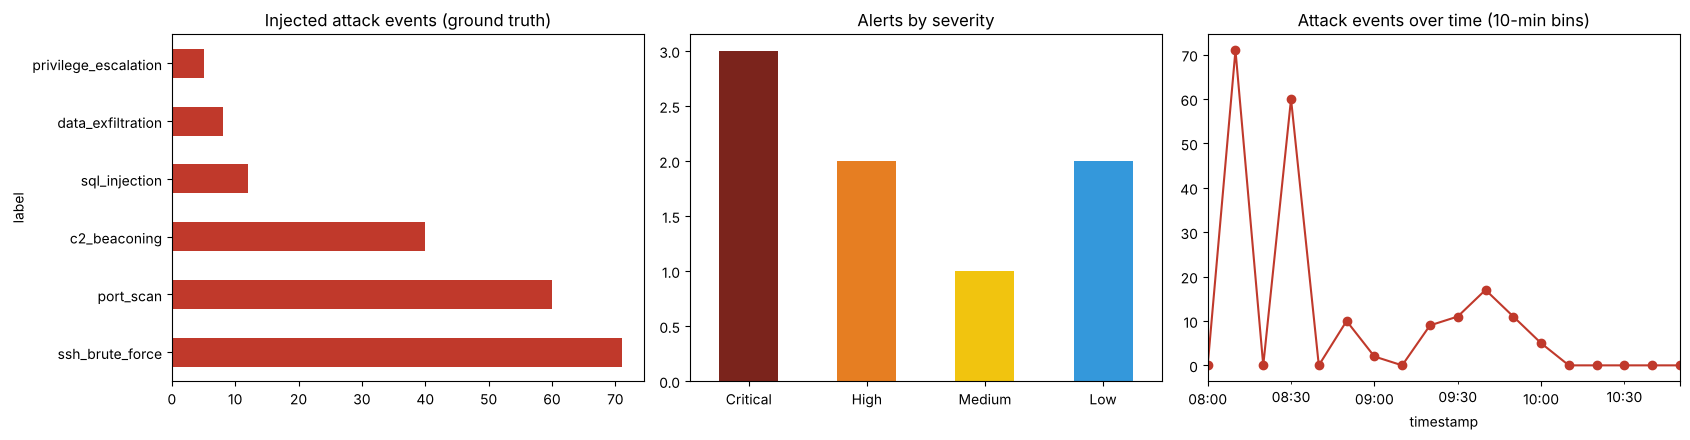

In [23]:
OUTPUT_DIR.mkdir(exist_ok=True)
plot_results(logs, result["alerts"], OUTPUT_DIR / "results.png");

## 17. Conclusion

- Every injected incident is detected and typed correctly and mapped to the right ATT&CK technique via RAG.
- Responses are derived from retrieved **playbooks** and restricted to a simulated allow-list.
- The same tools run under a live CrewAI crew (Gemini / Gemma / Groq) when an API key is available; if the live crew fails
  the notebook falls back to offline mode and says why.

*Limitations:* synthetic data with tuned thresholds, small knowledge base, simulated actions. See the repo's `docs/`.